<a href="https://colab.research.google.com/github/ishaanm73-blip/Neural-Networks/blob/main/Neural_Network_Creation_and_Training_4_(Multi_layered_Perceptron_in_NLP).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

We will try to improve on our previous bigram and trigram attempts using an MLP to NLP

In [117]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
%matplotlib inline

In [118]:
words = open('names.txt','r').read().splitlines()
words[:8]

['emma', 'olivia', 'ava', 'isabella', 'sophia', 'charlotte', 'mia', 'amelia']

In [119]:
len(words)

32033

In [120]:
chars = sorted(list(set(''.join(words))))
stoi = {s:i+1 for i,s in enumerate(chars)}
stoi['.'] = 0
itos = {i:s for s,i in stoi.items()}
print(itos)

{1: 'a', 2: 'b', 3: 'c', 4: 'd', 5: 'e', 6: 'f', 7: 'g', 8: 'h', 9: 'i', 10: 'j', 11: 'k', 12: 'l', 13: 'm', 14: 'n', 15: 'o', 16: 'p', 17: 'q', 18: 'r', 19: 's', 20: 't', 21: 'u', 22: 'v', 23: 'w', 24: 'x', 25: 'y', 26: 'z', 0: '.'}


In [121]:
block_size = 3
X, Y = [], []
for w in words:
    #print(w)
    context = [0] * block_size #So this one creates a list [0,0,0] for block_size 3
    for ch in w + '.':
      ix = stoi[ch]
      X.append(context)
      Y.append(ix)
      #print(''.join(itos[i] for i in context), '--->', itos[ix])
      context = context[1:] + [ix]
X = torch.tensor(X)
Y = torch.tensor(Y)

In [122]:
X.shape,X.dtype,Y.shape,Y.dtype

(torch.Size([228146, 3]), torch.int64, torch.Size([228146]), torch.int64)

In [123]:
C = torch.rand(27,2)

In [124]:
C[5]

tensor([0.8872, 0.6800])

Another way of doing the same thing

In [125]:
F.one_hot(torch.tensor(5), num_classes=27).float() @ C

tensor([0.8872, 0.6800])

In [126]:
C[torch.tensor([5,6,7,7,7,7])]

tensor([[0.8872, 0.6800],
        [0.9804, 0.6076],
        [0.7145, 0.6804],
        [0.7145, 0.6804],
        [0.7145, 0.6804],
        [0.7145, 0.6804]])

In [127]:
C[X].shape

torch.Size([228146, 3, 2])

In [128]:
X[13,2]

tensor(1)

In [129]:
C[X][13,2]

tensor([0.8471, 0.9001])

In [130]:
emb = C[X]
emb.shape

torch.Size([228146, 3, 2])

In [131]:
W1 = torch.rand((6,100))
b1 = torch.rand(100)

we want to do emb*W1 + B1, but the problem is that emb is [32,2,3] and W1 is [6,100] so we concatenate the individual word embeddings of emb so that we get an embedding matrix that can be operated on with W1

In [132]:
torch.cat([emb[:,0,:],emb[:,1,:],emb[:,2,:]],1).shape

torch.Size([228146, 6])

to split the rows of the embed matrix which is of any dimension we use the unbind function to individually extract the rows instead of doing emb[:,1,:] n number of times and then we just concaatenate it

In [133]:
torch.cat(torch.unbind(emb,1),1).shape #VERY INEFFICIENT AS IT CREATES A NEW TENSOR WITH A NEW MEMORY EVERY SINGLE TIME

torch.Size([228146, 6])

let us understaand the view function

In [134]:
a = torch.arange(18)

In [135]:
a

tensor([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16, 17])

In [136]:
a.view(3,3,2)

tensor([[[ 0,  1],
         [ 2,  3],
         [ 4,  5]],

        [[ 6,  7],
         [ 8,  9],
         [10, 11]],

        [[12, 13],
         [14, 15],
         [16, 17]]])

In [137]:
a.view(3,2,3)

tensor([[[ 0,  1,  2],
         [ 3,  4,  5]],

        [[ 6,  7,  8],
         [ 9, 10, 11]],

        [[12, 13, 14],
         [15, 16, 17]]])

In [138]:
a.storage()

 0
 1
 2
 3
 4
 5
 6
 7
 8
 9
 10
 11
 12
 13
 14
 15
 16
 17
[torch.storage.TypedStorage(dtype=torch.int64, device=cpu) of size 18]

so lets finally make the neural function finally, we are also using -1 here so that the code automatically calculates the values of the net embedding matrix in case we change the scale of the dataset

In [139]:
h = emb.view(-1,6) @ W1 + b1

In [140]:
h.shape

torch.Size([228146, 100])

we are wrapping the h in the wrapper function of tanh so that we can make the neural network calculations happen properly

In [141]:
h = torch.tanh(emb.view(-1,6) @ W1 + b1)

In [142]:
h.shape

torch.Size([228146, 100])

In [143]:
W2 = torch.rand((100,27))
b2 = torch.rand(27)

In [144]:
logits = h @ W2 + b2

In [145]:
logits.shape

torch.Size([228146, 27])

In [146]:
counts = logits.exp()
probs = (counts/counts.sum(1,keepdims=True))

In [147]:
loss = -probs[torch.arange(228146),Y].log().mean()
loss

tensor(6.5990)

Now this thing has a little problems with respect to kernels, lets look at an example that breaks the brain of this function/method

In [148]:
logits = torch.tensor([-100,-3,4,100])
counts = logits.exp()
probs = counts/counts.sum()
probs

tensor([0., 0., 0., nan])

we can see here that for a very high value of logits...that when exponentiated exceeds the limit of floating type variables. So we use the cross_entropy function of torch.nn.functional

In [149]:
X.shape,Y.shape

(torch.Size([228146, 3]), torch.Size([228146]))

In [150]:
g = torch.Generator().manual_seed(2147483647)
C = torch.randn((27, 2), generator=g)
W1 = torch.randn((6, 100), generator=g)
b1 = torch.randn(100, generator=g)
W2 = torch.randn((100, 27), generator=g)
b2 = torch.randn(27, generator=g)
parameters = [C, W1, b1, W2, b2]

In [151]:
for p in parameters:
  p.requires_grad = True

In [152]:
for _ in range(100):
  #forward pass
  emb = C[X]
  h = torch.tanh(emb.view(-1, 6) @ W1 + b1)
  logits = (h @ W2 + b2)
  loss = F.cross_entropy(logits, Y)
  #backward pass
  for p in parameters:
    p.grad = None
  loss.backward()
  #update
  for p in parameters:
    p.data -= 0.1 * p.grad

print(loss.item())

3.5892493724823


In [153]:
for p in parameters:
  p.requires_grad = True
for _ in range(100):
  #creating a minibatch for training
  ix = torch.randint(0,X.shape[0],(32,))
  #forward pass
  emb = C[X[ix]]
  h = torch.tanh(emb.view(-1, 6) @ W1 + b1)
  logits = (h @ W2 + b2)
  loss = F.cross_entropy(logits, Y[ix])
  #backward pass
  for p in parameters:
    p.grad = None
  loss.backward()
  print(loss.item())
  #update
  for p in parameters:
    p.data -= 1 * p.grad



3.533684730529785
6.730702877044678
8.14245891571045
9.538561820983887
8.529535293579102
7.608903884887695
9.615928649902344
10.846341133117676
10.081975936889648
9.650732040405273
9.550419807434082
9.304783821105957
9.910262107849121
9.384906768798828
10.359810829162598
10.298422813415527
11.174825668334961
11.149454116821289
7.859370231628418
7.860438823699951
7.442988872528076
8.939916610717773
7.490480899810791
8.696634292602539
9.732976913452148
10.282964706420898
9.238618850708008
10.795136451721191
8.419341087341309
8.40180778503418
7.7123260498046875
7.338371753692627
7.074911594390869
7.224580764770508
6.672418594360352
7.40591287612915
7.1441521644592285
6.36093282699585
7.420971393585205
7.228628635406494
5.850677490234375
6.4510908126831055
10.368451118469238
9.714287757873535
8.597289085388184
9.460575103759766
9.995296478271484
8.67801570892334
7.278432846069336
8.244379043579102
6.825974464416504
7.75638484954834
7.298096656799316
7.544290065765381
8.9469575881958
9.9330

Now, lets tune the learning rate of the model

In [154]:
lre = torch.linspace(-3,0,1000)
lrs = 10**lre
lrs

tensor([0.0010, 0.0010, 0.0010, 0.0010, 0.0010, 0.0010, 0.0010, 0.0010, 0.0011,
        0.0011, 0.0011, 0.0011, 0.0011, 0.0011, 0.0011, 0.0011, 0.0011, 0.0011,
        0.0011, 0.0011, 0.0011, 0.0012, 0.0012, 0.0012, 0.0012, 0.0012, 0.0012,
        0.0012, 0.0012, 0.0012, 0.0012, 0.0012, 0.0012, 0.0013, 0.0013, 0.0013,
        0.0013, 0.0013, 0.0013, 0.0013, 0.0013, 0.0013, 0.0013, 0.0013, 0.0014,
        0.0014, 0.0014, 0.0014, 0.0014, 0.0014, 0.0014, 0.0014, 0.0014, 0.0014,
        0.0015, 0.0015, 0.0015, 0.0015, 0.0015, 0.0015, 0.0015, 0.0015, 0.0015,
        0.0015, 0.0016, 0.0016, 0.0016, 0.0016, 0.0016, 0.0016, 0.0016, 0.0016,
        0.0016, 0.0017, 0.0017, 0.0017, 0.0017, 0.0017, 0.0017, 0.0017, 0.0017,
        0.0018, 0.0018, 0.0018, 0.0018, 0.0018, 0.0018, 0.0018, 0.0018, 0.0019,
        0.0019, 0.0019, 0.0019, 0.0019, 0.0019, 0.0019, 0.0019, 0.0020, 0.0020,
        0.0020, 0.0020, 0.0020, 0.0020, 0.0020, 0.0021, 0.0021, 0.0021, 0.0021,
        0.0021, 0.0021, 0.0021, 0.0022, 

In [155]:
lri = []
lossi = []
for p in parameters:
  p.requires_grad = True
for i in range(1000):
  #creating a minibatch for training
  ix = torch.randint(0,X.shape[0],(32,))
  #forward pass
  emb = C[X[ix]]
  h = torch.tanh(emb.view(-1, 6) @ W1 + b1)
  logits = (h @ W2 + b2)
  loss = F.cross_entropy(logits, Y[ix])
  #backward pass
  for p in parameters:
    p.grad = None
  loss.backward()
  #update
  lr = lrs[i]
  for p in parameters:
    p.data -= lr * p.grad
  #note the values of learning rate
  lri.append(lr)
  lossi.append(loss.item())
print(loss.item())

6.285879611968994


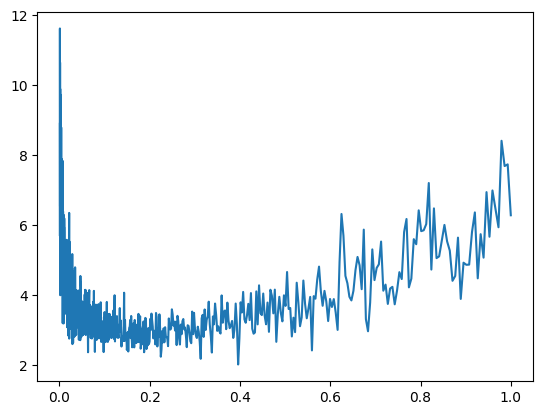

In [156]:
plt.plot(lri,lossi)

In [157]:
for p in parameters:
  p.requires_grad = True

In [158]:
lri = []
lossi = []
for i in range(1000):
  #creating a minibatch for training
  ix = torch.randint(0,X.shape[0],(32,))
  #forward pass
  emb = C[X[ix]]
  h = torch.tanh(emb.view(-1, 6) @ W1 + b1)
  logits = (h @ W2 + b2)
  loss = F.cross_entropy(logits, Y[ix])
  #backward pass
  for p in parameters:
    p.grad = None
  loss.backward()
  #update
  lr = 0.1
  for p in parameters:
    p.data -= lr * p.grad
  #note the values of learning rate
  lri.append(lr)
  lossi.append(loss.item())
print(loss.item())

2.52398943901062


lets do train test split

In [159]:
import random
random.seed(42)
random.shuffle(words)
n1 = int(0.8 * len(words))
n2 = int(0.9 * len(words))
Xtrain = X[:n1]
Ytrain = Y[:n1]
Xdev = X[n1:n2]
Ydev = Y[n1:n2]
Xtest = X[n2:]
Ytest = Y[n2:]

Xtrain.shape,Ytrain.shape,Xdev.shape,Ydev.shape,Xtest.shape,Ytest.shape

(torch.Size([25626, 3]),
 torch.Size([25626]),
 torch.Size([3203, 3]),
 torch.Size([3203]),
 torch.Size([199317, 3]),
 torch.Size([199317]))

now lets do separate sampling

In [160]:
def build_dataset(words):
  block_size = 3
  X, Y = [], []
  for w in words:
    context = [0] * block_size
    for ch in w + '.':
      ix = stoi[ch]
      X.append(context)
      Y.append(ix)
      context = context[1:] + [ix]

  X = torch.tensor(X)
  Y = torch.tensor(Y)
  print(X.shape,Y.shape)
  return X,Y

In [161]:
Xtr = build_dataset(words[:n1])
Xdev = build_dataset(words[n1:n2])
Xte = build_dataset(words[n2:])
Ytr = build_dataset(words[:n1])
Ydev = build_dataset(words[n1:n2])
Yte = build_dataset(words[n2:])

torch.Size([182625, 3]) torch.Size([182625])
torch.Size([22655, 3]) torch.Size([22655])
torch.Size([22866, 3]) torch.Size([22866])
torch.Size([182625, 3]) torch.Size([182625])
torch.Size([22655, 3]) torch.Size([22655])
torch.Size([22866, 3]) torch.Size([22866])


so lets train  using the train and dev splits

In [180]:
g = torch.Generator().manual_seed(2147483647)
C = torch.randn((27, 30), generator=g)
W1 = torch.randn((90, 300), generator=g) # 3 characters * 30 dimensions = 90 input features
b1 = torch.randn(300, generator=g)
W2 = torch.randn((300, 27), generator=g)
b2 = torch.randn(27, generator=g)
parameters = [C, W1, b1, W2, b2]

In [181]:
for p in parameters:
  p.requires_grad = True

In [182]:
lri = []
lossi = []
stepi = []
# Unpacking the feature and target tensors from the dataset tuples
Xtr_tensor, _ = Xtr
_, Ytr_tensor = Ytr

for p in parameters:
  p.requires_grad = True

for i in range(200000):
  # creating a minibatch for training
  ix = torch.randint(0, Xtr_tensor.shape[0], (32,))
  # forward pass
  emb = C[Xtr_tensor[ix]]
  h = torch.tanh(emb.view(-1, 90) @ W1 + b1) # Reshaping to 90 features (3 * 30D)
  logits = (h @ W2 + b2)
  loss = F.cross_entropy(logits, Ytr_tensor[ix])
  # backward pass
  for p in parameters:
    p.grad = None
  loss.backward()
  # update
  lr = 0.1 if i < 50000 else 0.01
  for p in parameters:
    p.data -= lr * p.grad
  # note the values of learning rate
  lri.append(lr)
  stepi.append(i)
  lossi.append(loss.item())
print(loss.item())

2.063685655593872


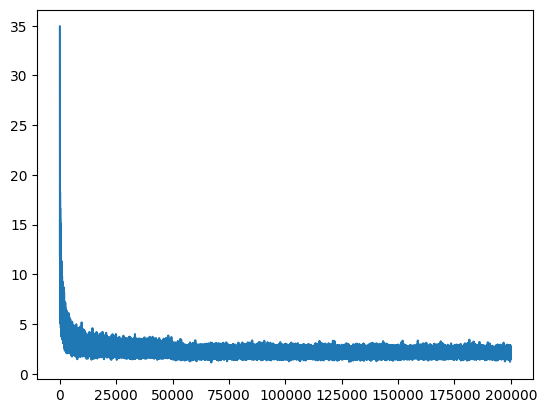

In [185]:
plt.plot(stepi,lossi)

In [183]:
Xtr_tensor = Xtr[0]
Ytr_tensor = Ytr[1]
emb = C[Xtr_tensor]
h = torch.tanh(emb.view(-1, 90) @ W1 + b1)
logits = h @ W2 + b2
loss = F.cross_entropy(logits, Ytr_tensor)
loss.item()

2.0544705390930176

In [184]:
Xdev_tensor = Xdev[0]
Ydev_tensor = Ydev[1]
emb = C[Xdev_tensor]
h = torch.tanh(emb.view(-1, 90) @ W1 + b1)
logits = h @ W2 + b2
loss = F.cross_entropy(logits, Ydev_tensor)
loss.item()

2.169708251953125